# Exploratory data analysis

Smart Code Complexity Predictor, Phase 8. Every table and figure below is computed from the processed datasets in `data/processed/` (built by `python -m src.dataset_loader build`). The same functions also produce `reports/eda/eda_report.md` via `python -m src.eda`.

Correlations here are associations in this data. They do not show that a feature causes a label.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import display
from src import config, eda
from src.feature_extractor import FILE_FEATURE_NAMES, FUNCTION_FEATURE_NAMES

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
F, G = list(FILE_FEATURE_NAMES), list(FUNCTION_FEATURE_NAMES)
bigo = eda.load_bigo()
struct = eda.load_structural()
sources = eda.attach_sources(bigo, config.CODECOMPLEX_DIR / config.CODECOMPLEX['file'])
print(f'Big-O dataset: {bigo.shape}, structural dataset: {struct.shape}, raw sources available: {sources is not None}')

Big-O dataset: (4458, 52), structural dataset: (3910, 48), raw sources available: True


## 1–3. Dimensions, feature names, data types, missing values

In [2]:
display(pd.DataFrame({'Big-O (CodeComplex)': eda.overview(bigo, F), 'Structural (TheAlgorithms)': eda.overview(struct, G)}))

,Big-O (CodeComplex),Structural (TheAlgorithms)
rows,4458,3910
columns,52,48
feature_columns,39,36
metadata_columns,13,12
feature_dtypes,"{'int64': 35, 'float64': 4}","{'int64': 34, 'float64': 2}"
missing_values,0,0
empty_metadata_strings,{},{}
constant_features,[],[]
mostly_zero_features,"[docstring_lines, try_count, except_count]","[function_count, class_count, elif_count, try_..."


In [3]:
print('Big-O features:', ', '.join(F))
bigo.head(3)

Big-O features: total_lines, code_lines, blank_lines, comment_lines, docstring_lines, comment_ratio, function_count, class_count, average_function_length, maximum_function_length, return_count, if_count, elif_count, else_count, for_loop_count, while_loop_count, loop_count, try_count, except_count, conditional_expression_count, comprehension_count, cyclomatic_complexity, average_function_cyclomatic_complexity, maximum_function_cyclomatic_complexity, maximum_nesting_depth, average_nesting_depth, nested_loop_count, maximum_loop_nesting_depth, recursive_call_count, import_count, identifier_count, unique_identifier_count, operator_count, arithmetic_operator_count, comparison_operator_count, logical_operator_count, bitwise_operator_count, function_call_count, collection_literal_count


,sample_id,source_dataset,source_commit,raw_index,problem,tags,label,label_name,label_bigo,label_rank,label_method,near_duplicate_cluster,code_sha256,total_lines,code_lines,blank_lines,comment_lines,docstring_lines,comment_ratio,function_count,class_count,average_function_length,maximum_function_length,return_count,if_count,elif_count,else_count,for_loop_count,while_loop_count,loop_count,try_count,except_count,conditional_expression_count,comprehension_count,cyclomatic_complexity,average_function_cyclomatic_complexity,maximum_function_cyclomatic_complexity,maximum_nesting_depth,average_nesting_depth,nested_loop_count,maximum_loop_nesting_depth,recursive_call_count,import_count,identifier_count,unique_identifier_count,operator_count,arithmetic_operator_count,comparison_operator_count,logical_operator_count,bitwise_operator_count,function_call_count,collection_literal_count
0,codecomplex-py-00000,CodeComplex (Python subset),c54631de24c0c3b0e180e876a9f244fb0905cf86,0,0005_D,"implementation,math",constant,constant,O(1),0,"expert annotation (CodeComplex authors), whole...",-1,1d149bbfcd836030dec0cde2c63256710e52f9453a48fa...,24,20,4,0,0,0.0000,2,0,8.0000,11,4,3,0,1,0,0,0,0,0,0,0,5,3.0,4,1,0.2632,0,0,0,1,94,20,44,39,4,1,0,12,0
1,codecomplex-py-00001,CodeComplex (Python subset),c54631de24c0c3b0e180e876a9f244fb0905cf86,1,0005_D,"implementation,math",constant,constant,O(1),0,"expert annotation (CodeComplex authors), whole...",-1,5821a8f3bddec85ef9fb70f89ba9d360bea0a28b8bdeb8...,21,21,0,0,0,0.0000,0,0,0.0000,0,0,4,0,4,0,0,0,0,0,0,0,6,0.0,0,2,1.1176,0,0,0,1,88,14,70,64,5,1,0,11,0
2,codecomplex-py-00002,CodeComplex (Python subset),c54631de24c0c3b0e180e876a9f244fb0905cf86,2,0005_D,"implementation,math",constant,constant,O(1),0,"expert annotation (CodeComplex authors), whole...",-1,466e46f85b516351ad0e5beb4458c040da522b33a484d7...,165,126,28,12,5,0.0876,14,2,6.6429,42,15,6,0,4,0,2,2,0,0,1,3,15,2.0,6,2,0.5490,0,1,0,15,312,68,90,76,10,4,0,55,4


## 4. Duplicate records

Exact and renamed duplicates were removed in Phase 7. Here we check what remains: repeated ids or code hashes, and different programs that happen to share a feature vector.

In [4]:
display(pd.DataFrame({'Big-O': eda.duplicate_summary(bigo, F, 'label'), 'Structural': eda.duplicate_summary(struct, G, 'reference_label')}))

,Big-O,Structural
duplicate_sample_ids,0.0,0.0
duplicate_code_hashes,0.0,0.0
rows_sharing_a_feature_vector,95.0,221.0
feature_vectors_with_conflicting_labels,0.0,0.0
rows_in_conflicting_vectors,0.0,0.0
accuracy_ceiling_from_features,1.0,1.0


Some programs share a feature vector, because the features summarise structure rather than the code itself. None of these shared vectors carry conflicting labels.

## 5. Complexity class distribution

,count,percent
label_bigo,,
O(1),683,15.32
O(log n),581,13.03
O(n),801,17.97
O(n log n),757,16.98
O(n^2),615,13.80
O(n^3),540,12.11
O(2^n),481,10.79


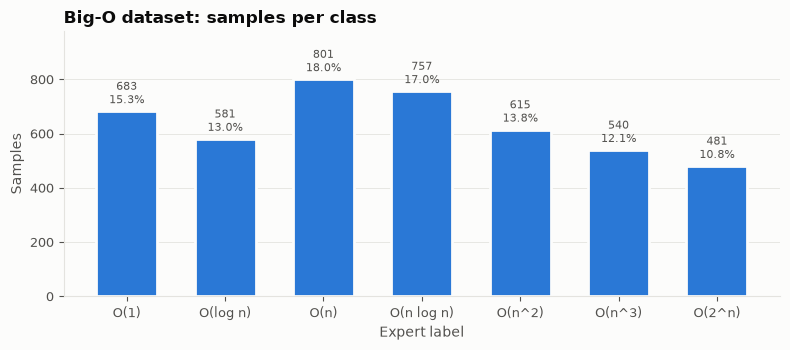

In [5]:
dist = eda.class_distribution(bigo['label_bigo'].astype(str), eda.BIGO_ORDER)
eda.plot_class_distribution(dist, 'Big-O dataset: samples per class', 'Expert label');
dist

,count,percent
reference_label,,
Low,3245,82.99
Medium,549,14.04
High,116,2.97


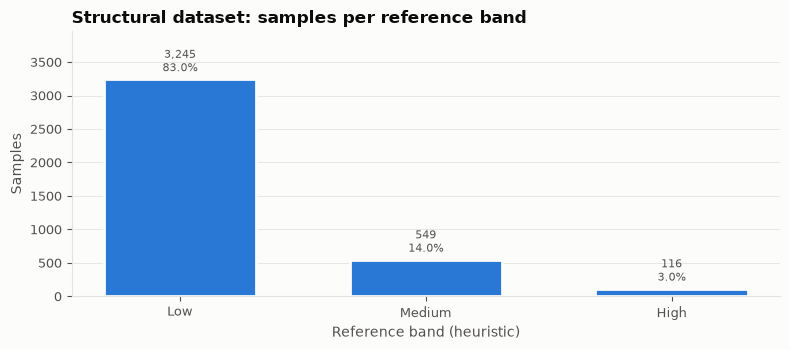

In [6]:
bands = eda.class_distribution(struct['reference_label'].astype(str), eda.BAND_ORDER)
eda.plot_class_distribution(bands, 'Structural dataset: samples per reference band', 'Reference band (heuristic)');
bands

The Big-O classes are mildly imbalanced. The structural bands are heavily imbalanced (few High functions), and they are heuristic bands, not human labels (see section 10).

## 6. Feature distributions

,mean,median,std,min,max,zero_%,skew
total_lines,38.63,24.0,58.70,1.0,753.00,0.00,6.51
code_lines,30.81,20.0,45.38,1.0,659.00,0.00,7.53
blank_lines,6.25,2.0,17.57,0.0,362.00,30.53,11.87
comment_lines,1.67,0.0,5.00,0.0,92.00,66.89,6.86
docstring_lines,0.28,0.0,2.05,0.0,34.00,96.52,10.27
comment_ratio,0.04,0.0,0.08,0.0,0.97,66.89,4.20
function_count,1.79,0.0,5.12,0.0,61.00,60.18,6.60
class_count,0.19,0.0,0.90,0.0,12.00,92.71,7.71
average_function_length,4.41,0.0,8.45,0.0,101.00,60.18,3.46
maximum_function_length,7.21,0.0,18.32,0.0,376.00,60.18,10.63


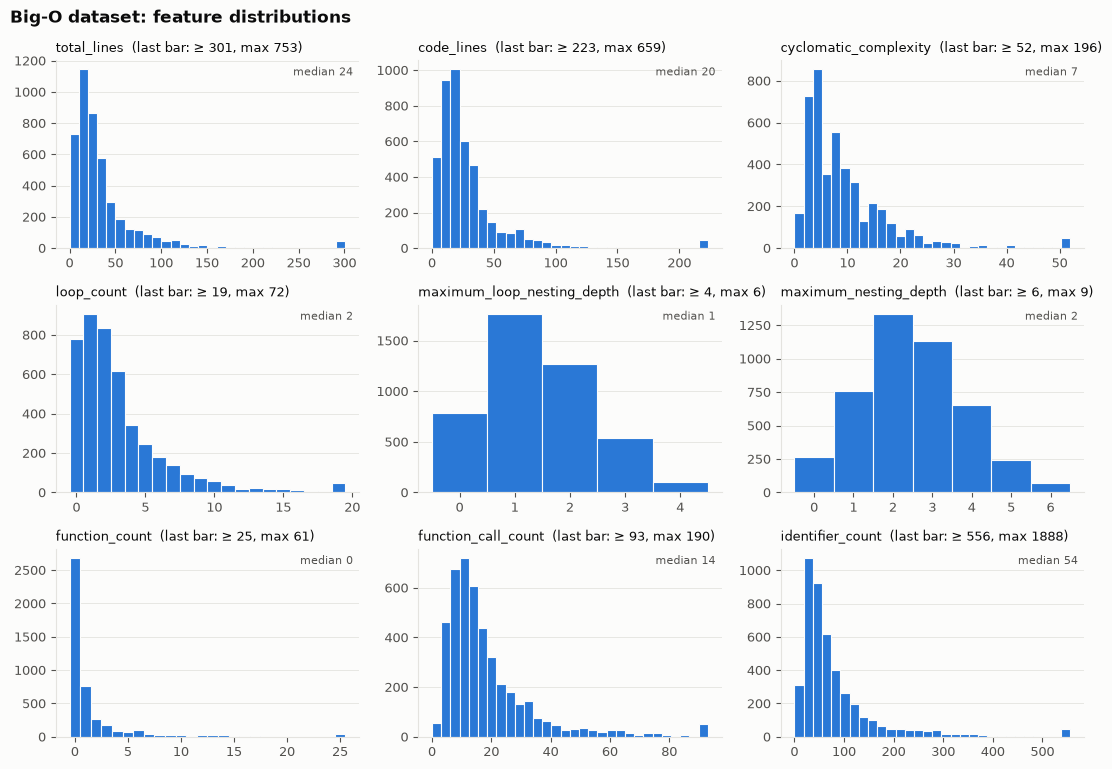

In [7]:
eda.plot_feature_histograms(bigo, eda.HIST_FEATURES, 'Big-O dataset: feature distributions');
eda.feature_summary(bigo, F)

Count features are right-skewed, with long tails. Each histogram shows values up to the 99th percentile; the last bar groups the top 1%.

## 7. Correlation between features

,feature_a,feature_b,spearman
0,try_count,except_count,1.000
1,average_function_length,average_function_cyclomatic_complexity,0.990
2,maximum_function_length,maximum_function_cyclomatic_complexity,0.989
3,average_function_cyclomatic_complexity,maximum_function_cyclomatic_complexity,0.984
4,average_function_length,maximum_function_length,0.984
5,comment_lines,comment_ratio,0.981
6,average_function_length,maximum_function_cyclomatic_complexity,0.976
7,maximum_function_length,average_function_cyclomatic_complexity,0.974
8,total_lines,code_lines,0.973


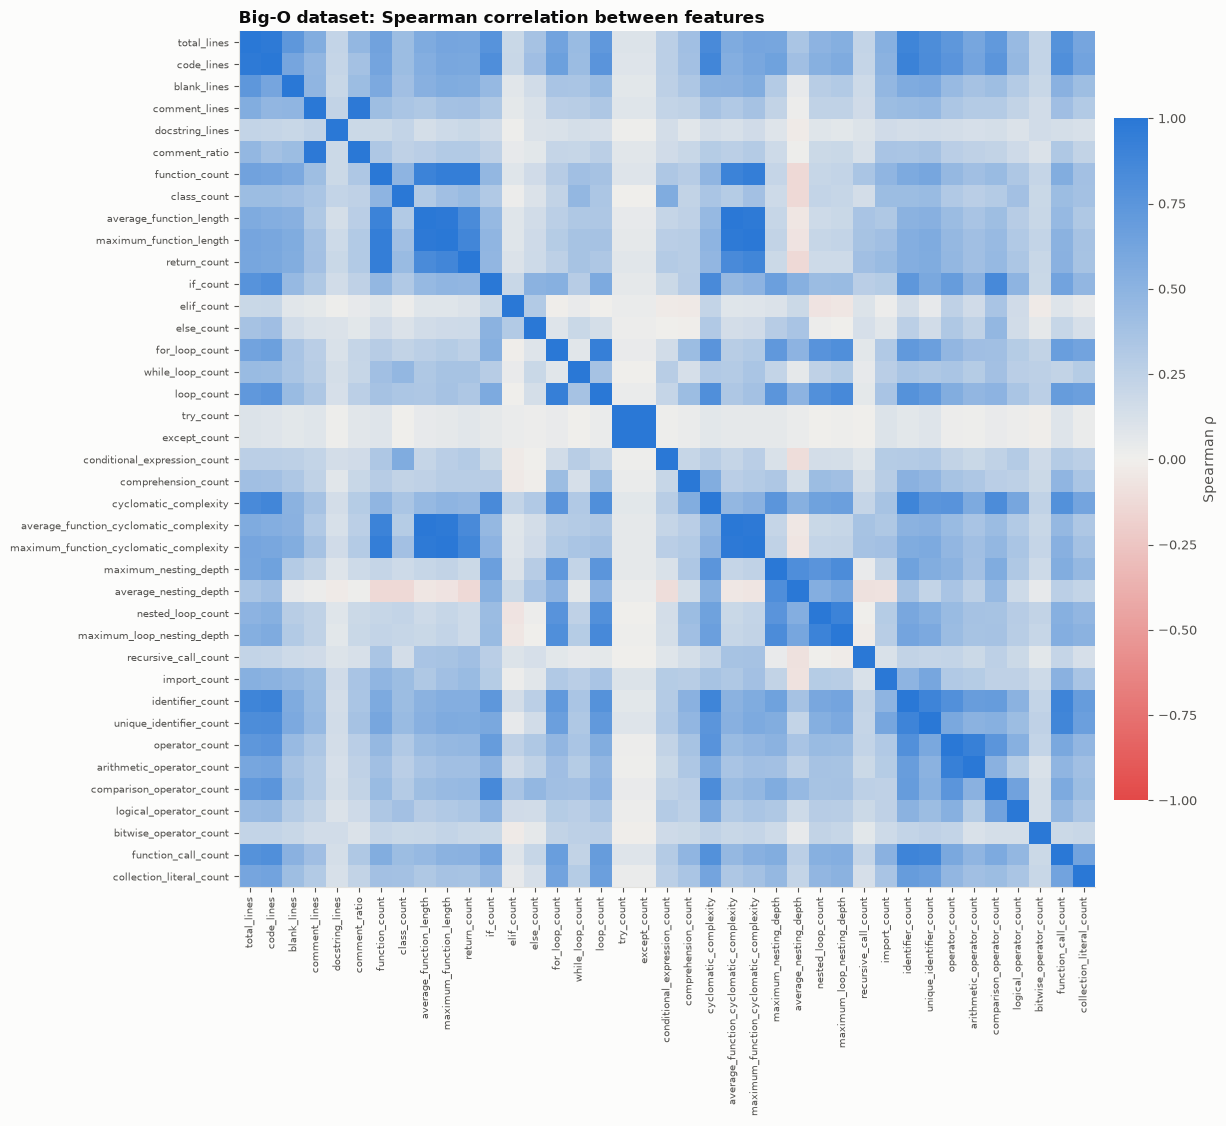

In [8]:
eda.plot_correlation_heatmap(bigo, F, 'Big-O dataset: Spearman correlation between features');
eda.redundant_pairs(bigo, F)

Several pairs are redundant by construction (for example `loop_count = for_loop_count + while_loop_count`, and `comment_ratio` is derived from `comment_lines`). Linear models need one of each pair removed, or regularisation.

## 8. Outliers

In [9]:
eda.outlier_summary(bigo, F).head(12)

,outliers,outlier_%,q1,q3,iqr,max
elif_count,635,14.24,0.0,0.000000,0.000000,21.0000
bitwise_operator_count,605,13.57,0.0,0.000000,0.000000,49.0000
conditional_expression_count,515,11.55,0.0,0.000000,0.000000,6.0000
function_count,482,10.81,0.0,1.000000,1.000000,61.0000
import_count,473,10.61,0.0,1.000000,1.000000,40.0000
comment_lines,429,9.62,0.0,1.000000,1.000000,92.0000
class_count,325,7.29,0.0,0.000000,0.000000,12.0000
recursive_call_count,314,7.04,0.0,0.000000,0.000000,10.0000
comment_ratio,289,6.48,0.0,0.039875,0.039875,0.9688
logical_operator_count,239,5.36,0.0,1.000000,1.000000,67.0000


In [10]:
cols = ['sample_id', 'label_bigo', 'total_lines', 'class_count', 'function_count', 'maximum_loop_nesting_depth']
bigo.nlargest(5, 'total_lines')[cols]

,sample_id,label_bigo,total_lines,class_count,function_count,maximum_loop_nesting_depth
2870,codecomplex-py-03162,O(n^2),753,12,59,4
178,codecomplex-py-00204,O(1),748,12,59,4
3751,codecomplex-py-04126,O(n^3),701,11,58,4
3563,codecomplex-py-03907,O(n^3),685,11,58,4
667,codecomplex-py-00775,O(1),680,11,58,4


Features that are mostly zero (IQR = 0) flag every non-zero value as an outlier, so their counts are high by construction. The longest programs consist mostly of template classes. Outliers are real submissions and are kept.

## 9. Relationships between metrics and labels

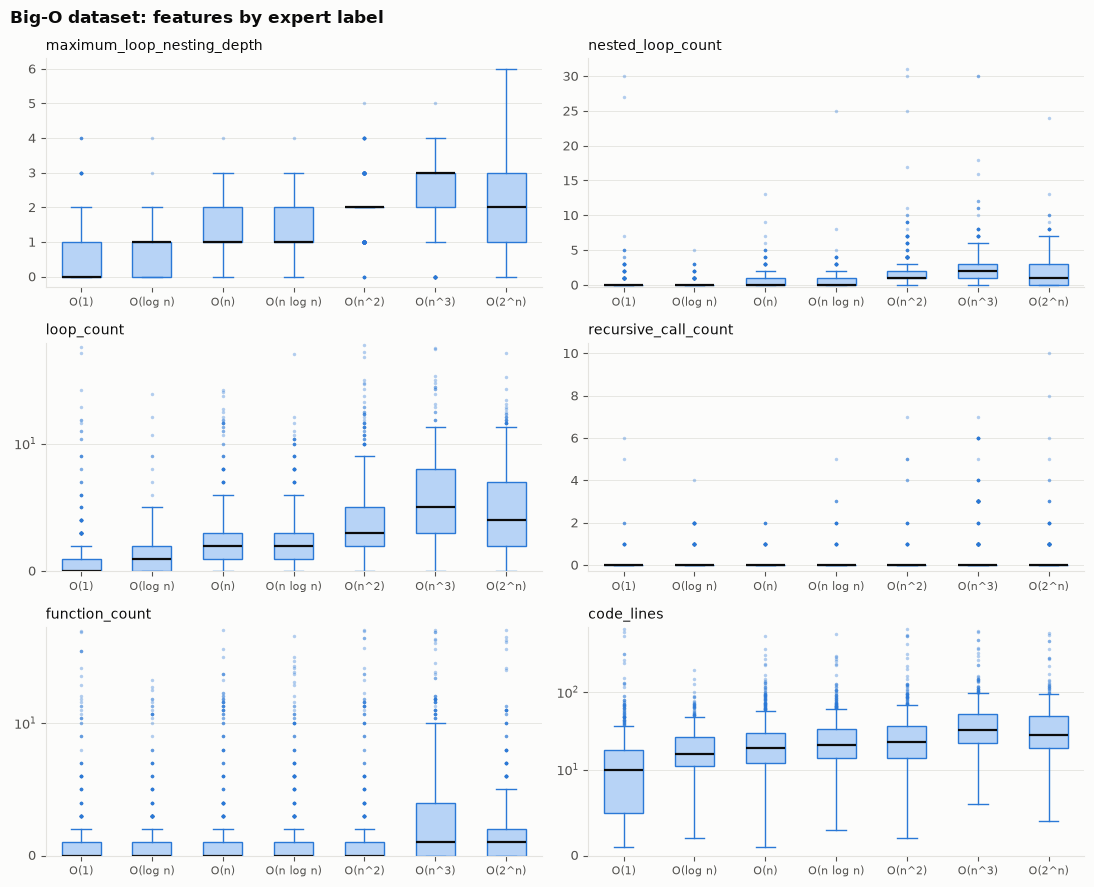

In [11]:
eda.plot_features_by_class(bigo, eda.LABEL_FEATURES, 'label_bigo', eda.BIGO_ORDER, 'Big-O dataset: features by expert label');

,spearman_with_label_rank
maximum_loop_nesting_depth,0.602
for_loop_count,0.590
nested_loop_count,0.567
loop_count,0.555
maximum_nesting_depth,0.523
identifier_count,0.514
function_call_count,0.512
unique_identifier_count,0.506
cyclomatic_complexity,0.506
code_lines,0.402


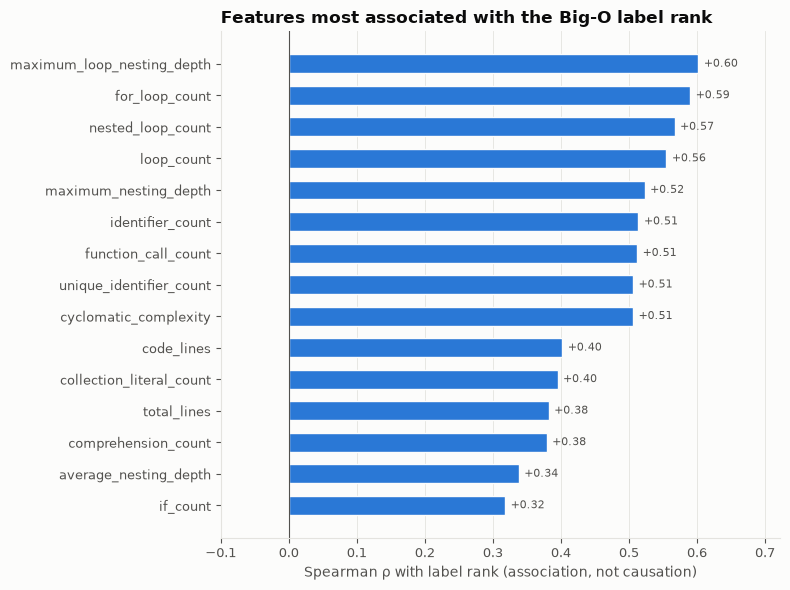

In [12]:
assoc = eda.feature_label_association(bigo, F, 'label_rank')
eda.plot_label_association(assoc, 'Features most associated with the Big-O label rank');
assoc.head(15)

In [13]:
eda.median_by_class(bigo, eda.LABEL_FEATURES, 'label_bigo')

label_bigo,O(1),O(log n),O(n),O(n log n),O(n^2),O(n^3),O(2^n)
maximum_loop_nesting_depth,0.0,1.0,1.0,1.0,2.0,3.0,2.0
nested_loop_count,0.0,0.0,0.0,0.0,1.0,2.0,1.0
loop_count,0.0,1.0,2.0,2.0,3.0,5.0,4.0
recursive_call_count,0.0,0.0,0.0,0.0,0.0,0.0,0.0
function_count,0.0,0.0,0.0,0.0,0.0,1.0,1.0
code_lines,10.0,16.0,19.0,21.0,23.0,32.0,28.0


Loop nesting rises with the label rank, which matches algorithm theory, but the classes overlap heavily: no single feature separates them. This is an association, not a causal effect. Recursion is rare even in O(2^n) programs, most of which enumerate bitmasks with loops.

## 10. Potential target leakage

In [14]:
purity = eda.problem_label_purity(bigo)
purity

{'problems': 275,
 'single_label_problems': 236,
 'single_label_problem_%': 85.8,
 'labels_per_problem': {1: 236, 2: 26, 3: 12, 4: 1},
 'samples_with_problem_majority_label_%': 95.6,
 'samples_per_problem': {'count': 275.0,
  'mean': 16.2,
  'std': 18.5,
  'min': 1.0,
  '25%': 8.0,
  '50%': 11.0,
  '75%': 18.0,
  'max': 135.0}}

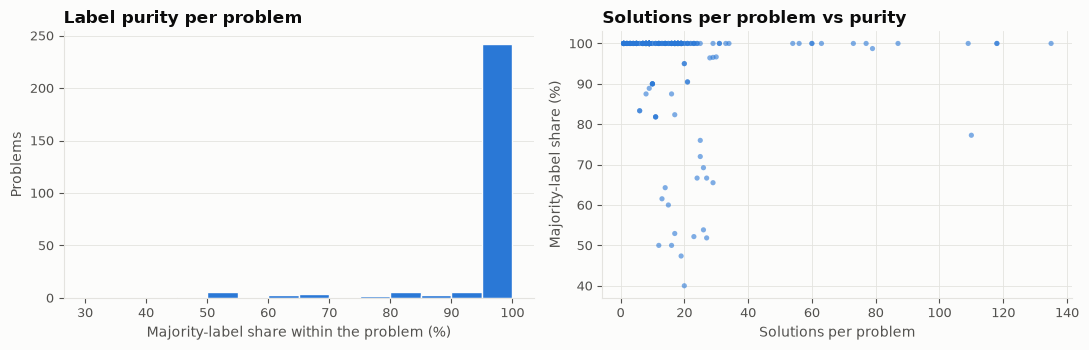

In [15]:
eda.plot_problem_purity(bigo);

Most problems have one label for all of their solutions. If solutions of the same problem appear in both training and test data, a model can score well by recognising the problem rather than the complexity. **Splits must be made by `problem`.**

In [16]:
eda.tag_label_table(bigo)

label_bigo,O(1),O(log n),O(n),O(n log n),O(n^2),O(n^3),O(2^n)
tag,,,,,,,
binary search,6.6,50.2,8.3,17.4,3.1,0.0,14.4
bitmasks,0.0,17.9,1.6,0.0,5.1,0.6,74.7
brute force,15.6,16.2,10.5,12.0,13.0,7.6,25.1
combinatorics,0.0,0.0,13.1,8.5,3.0,20.6,54.8
constructive algorithms,15.1,12.3,30.4,8.7,30.2,0.0,3.4
dp,3.5,13.2,9.1,3.3,11.6,36.4,22.9
graphs,5.6,0.0,14.7,12.7,16.2,37.2,13.6
greedy,4.5,8.7,23.4,26.0,10.3,25.4,1.7
implementation,17.5,13.7,24.8,19.2,23.9,0.1,0.9


Problem tags are strongly associated with labels (for example `bitmasks` with O(2^n)), but they are Codeforces metadata that user code does not have. They must not be used as features, and neither may the metadata columns.

### Circularity of the structural labels

In [17]:
circ = eda.structural_circularity(struct)
circ

{'rule_reproduces_label_%': 100.0,
 'cc_range_per_band': {'Low': {'min': 1, 'max': 5, 'count': 3245},
  'Medium': {'min': 6, 'max': 10, 'count': 549},
  'High': {'min': 11, 'max': 31, 'count': 116}},
 'features_with_rho_over_0.7': {'maximum_nesting_depth': 0.829,
  'average_nesting_depth': 0.82,
  'if_count': 0.801,
  'comparison_operator_count': 0.704}}

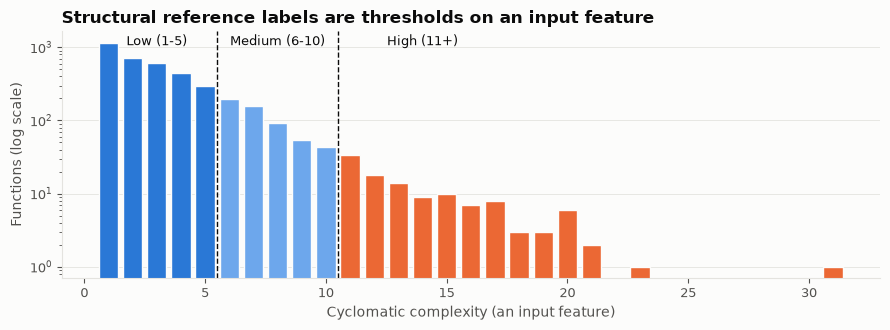

In [18]:
eda.plot_structural_circularity(struct);

The structural reference band is reproduced exactly by thresholds on `cyclomatic_complexity`, which is itself an input feature. Other features are strongly correlated with it. A model trained on these labels would only relearn the thresholds, so they are not a valid supervised target.

## 11. Near-duplicate samples

In [19]:
eda.near_duplicate_summary(bigo)

{'samples_in_clusters': 223,
 'clusters': 104,
 'largest_cluster': 5,
 'clusters_with_mixed_labels': 0,
 'clusters_spanning_problems': 0}

In [20]:
bigo[bigo['near_duplicate_cluster'] >= 0].groupby('near_duplicate_cluster')[['problem', 'label']].agg(lambda x: ', '.join(sorted(set(x)))).head(8)

,problem,label
near_duplicate_cluster,,
140,0343_A,constant
176,0483_A,constant
924,0287_B,logn
1155,0992_C,logn
1333,1177_B,logn
1508,0468_B,linear
1595,0914_C,linear
1640,0961_B,linear


Every near-duplicate cluster stays inside one problem with one label, so a problem-level split keeps each cluster on one side.

## 12. Possible dataset bias

In [21]:
eda.template_prevalence(bigo, sources)

label_bigo,O(1),O(log n),O(n),O(n log n),O(n^2),O(n^3),O(2^n),all
reads sys.stdin,10.5,11.2,16.2,19.6,23.3,35.7,31.2,20.2
FastIO class,2.3,2.6,3.6,4.0,3.9,12.0,8.5,4.9
raises recursion limit,3.4,3.6,3.7,3.6,3.9,8.7,6.9,4.6


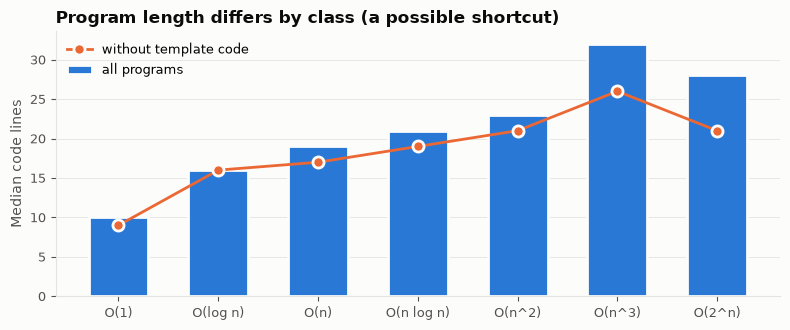

In [22]:
eda.plot_length_by_class(bigo, sources);

Template code (fast input readers, recursion-limit settings) is far more common in O(n^3) and O(2^n) programs. It inflates size features regardless of the algorithm, so a model could use program length as a shortcut that reflects author style. Other biases:

- a single source (Codeforces) and style: short single-file programs reading standard input;
- labels for whole programs, while the app analyses functions;
- concentration in a few hundred problems, so effective diversity is much smaller than the sample count;
- label noise: identical code with different labels was found and removed in Phase 7.

## Assessment

**Big-O dataset: suitable for training, with conditions.** It has thousands of expert-labelled real programs, reasonably balanced classes, no missing values, no conflicting duplicates, and features with a plausible association with the label. Honest results require:

1. grouped splits by `problem`, for both cross-validation and the held-out test set;
2. excluding tags and every metadata column from the features;
3. baselines: majority class, a loop-nesting rule, and the Phase 6 static analyser;
4. an ablation with and without size features, to detect a length shortcut;
5. careful wording: "agreement with expert labels on Codeforces-style programs", not general Big-O accuracy.

**Structural dataset: not suitable as a supervised target.** Its labels are thresholds on an input feature. It is useful for describing distributions and for calibrating the transparent rule-based structural score.